# Peso degli ordini k — plot

Legge i file prodotti da `notebooks/data_generation/peso_K_ordini.ipynb`
(`results/contributo_ordini/{res}_digits/{C_TYPE}/{ALGO}/contributo_ordini_{res}_digits_alpha_{tag}.parquet`).

- **ordine 0** = intrinsic complexity (Δ)
- **ordini k ≥ 1** = input complexity

Gli alpha disponibili vengono letti automaticamente dai nomi dei file: aggiungendo nuovi file i plot si aggiornano da soli.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path().resolve().parents[1]          # notebooks/plotting -> root del progetto
RESULTS = ROOT / "results" / "contributo_ordini"


## Configurazione

In [2]:
C_TYPE = "C_classica"                        # "C_classica" | "C_nilpotente"
ALGO   = "extended_fitness_no_imports"       # "extended_fitness_no_imports" | "extended_eci_no_imports"
RESOLUTIONS = [4, 6]
ALPHA_REF = 1.0                              # alpha del plot 1

SAVE_FIGS = True
FIG_DIR = RESULTS / "plots" / C_TYPE / ALGO
FIG_DIR.mkdir(parents=True, exist_ok=True)

# colori: una tinta per risoluzione, rampa sequenziale per alpha
RES_COLOR  = {4: "#2a78d6", 6: "#eb6834"}
RES_MARKER = {4: "o", 6: "s"}
ALPHA_CMAP = LinearSegmentedColormap.from_list("alpha_blue", ["#86b6ef", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "legend.frameon": False,
})

## Caricamento

In [3]:
ALPHA_RE = re.compile(r"alpha_(\d+)_(\d+)\.parquet$")

def tag_to_alpha(tag_int, tag_dec):
    return float(f"{tag_int}.{tag_dec}")

def load_pesi(res, c_type=C_TYPE, algo=ALGO):
    """Dict {alpha: pesi_df} per una risoluzione, ordinato per alpha."""
    folder = RESULTS / f"{res}_digits" / c_type / algo
    out = {}
    for f in folder.glob(f"contributo_ordini_{res}_digits_alpha_*.parquet"):
        m = ALPHA_RE.search(f.name)
        if m:
            out[tag_to_alpha(*m.groups())] = pd.read_parquet(f)
    if not out:
        raise FileNotFoundError(f"Nessun file in {folder}")
    return dict(sorted(out.items()))

pesi = {res: load_pesi(res) for res in RESOLUTIONS}
for res, d in pesi.items():
    print(f"{res} digits -> alpha disponibili: {list(d)}")

4 digits -> alpha disponibili: [0.001, 0.01, 0.1, 1.0]
6 digits -> alpha disponibili: [0.001, 0.01, 0.1, 1.0]


## Plot 1 — w(k) a α = 1, 4 vs 6 digits

Se ci fosse invarianza di risoluzione le due curve coinciderebbero. Il peso dell'ordine 0 (intrinsic complexity) è piccolo rispetto alla massa totale degli ordini successivi.

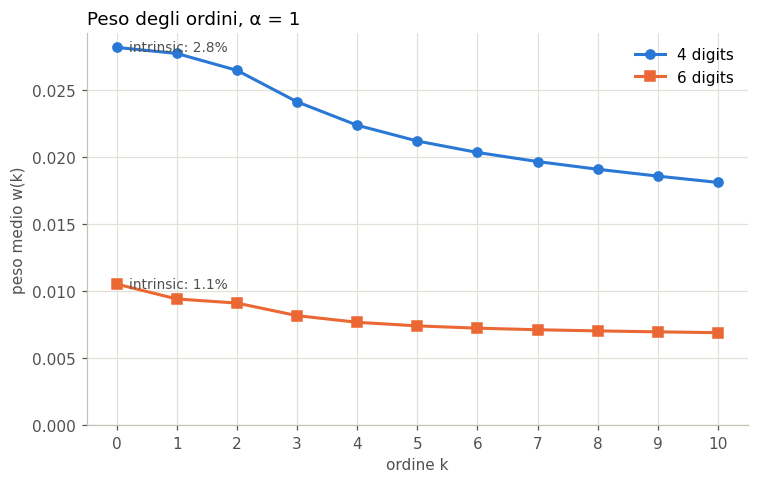

In [4]:
def plot_wk_resolutions(pesi, alpha=ALPHA_REF):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for res, d in pesi.items():
        if alpha not in d:
            print(f"alpha={alpha} mancante per {res} digits"); continue
        df = d[alpha]
        w0 = df["peso_medio"].iloc[0]
        ax.plot(df["ordine"], df["peso_medio"], marker=RES_MARKER[res],
                color=RES_COLOR[res], label=f"{res} digits")
        ax.annotate(f"intrinsic: {w0:.1%}", (0, w0), xytext=(8, 0),
                    textcoords="offset points", va="center", fontsize=9, color="#52514e")
    ax.set_xlabel("ordine k")
    ax.set_ylabel("peso medio w(k)")
    ax.set_title(f"Peso degli ordini, α = {alpha:g}", loc="left")
    ax.set_xticks(df["ordine"])
    ax.set_ylim(bottom=0)
    ax.legend()
    fig.tight_layout()
    if SAVE_FIGS:
        tag = f"{alpha:.3f}".replace(".", "_")
        fig.savefig(FIG_DIR / f"wk_4vs6_digits_alpha_{tag}.png", dpi=200)
    plt.show()

plot_wk_resolutions(pesi)

## Plot 2 — w(k) per diversi α (un pannello per risoluzione)

Scala log sulle y: al variare di α i pesi coprono molti ordini di grandezza.

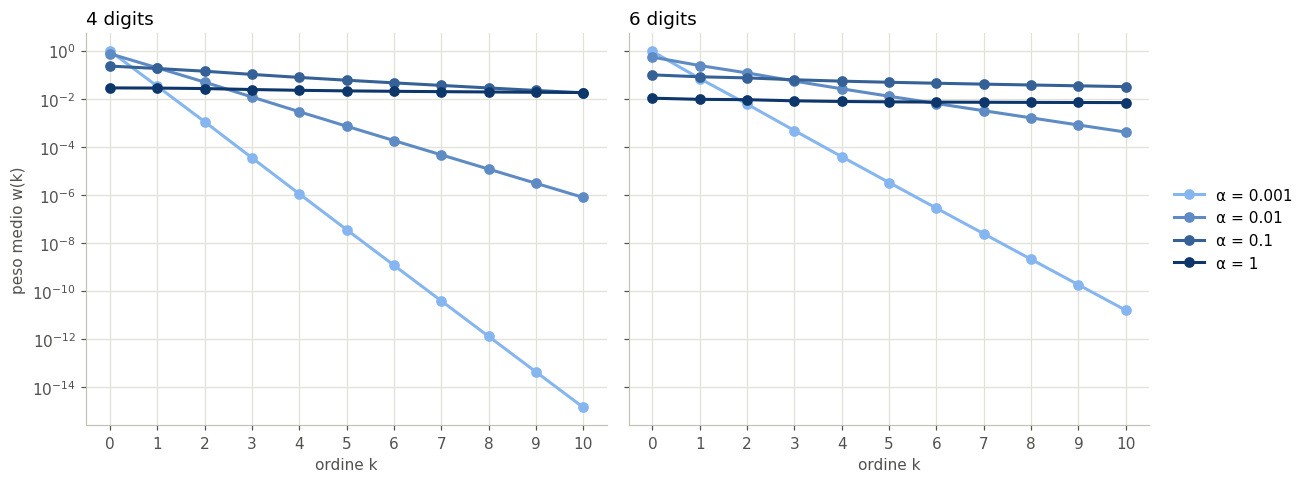

In [5]:
def plot_wk_alphas(pesi, logy=True):
    fig, axes = plt.subplots(1, len(pesi), figsize=(6 * len(pesi), 4.5), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (res, d) in zip(axes, pesi.items()):
        alphas = list(d)
        log_a = np.log10(alphas)
        norm = (log_a - log_a.min()) / (np.ptp(log_a) or 1)   # colore ~ log(alpha)
        for a, t in zip(alphas, norm):
            df = d[a]
            ax.plot(df["ordine"], df["peso_medio"], marker="o",
                    color=ALPHA_CMAP(t), label=f"α = {a:g}")
        ax.set_title(f"{res} digits", loc="left")
        ax.set_xlabel("ordine k")
        ax.set_xticks(df["ordine"])
        if logy:
            ax.set_yscale("log")
    axes[0].set_ylabel("peso medio w(k)")
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / "wk_vs_alpha.png", dpi=200)
    plt.show()

plot_wk_alphas(pesi)

## Plot 3 — peso totale intrinsic vs input al variare di α

- intrinsic = w(0)
- input = 1 − w(0)

L'input **non** è calcolato come Σ_{k=1}^{K-1} w(k), perché con K = 11 la serie è troncata: a α = 1 la somma dei primi 11 ordini arriva solo a ~0.25 (4 digits) e ~0.09 (6 digits). La colonna `somma_troncata` resta nella tabella come controllo.

In [6]:
def pesi_totali(pesi):
    rows = []
    for res, d in pesi.items():
        for a, df in d.items():
            w0 = df["peso_medio"].iloc[0]
            rows.append({"res": res, "alpha": a,
                         "intrinsic": w0,
                         "input": 1 - w0,
                         "somma_troncata": df["peso_cumulativo"].iloc[-1]})
    return pd.DataFrame(rows)

tot = pesi_totali(pesi)
tot

,res,alpha,intrinsic,input,somma_troncata
0,4,0.001,0.965940,0.034060,1.000000
1,4,0.010,0.742592,0.257408,1.000000
2,4,0.100,0.227833,0.772167,0.934613
3,4,1.000,0.028158,0.971842,0.245674
4,6,0.001,0.924811,0.075189,1.000000
5,6,0.010,0.537103,0.462897,0.999580
6,6,0.100,0.098091,0.901909,0.604125
7,6,1.000,0.010516,0.989484,0.087497


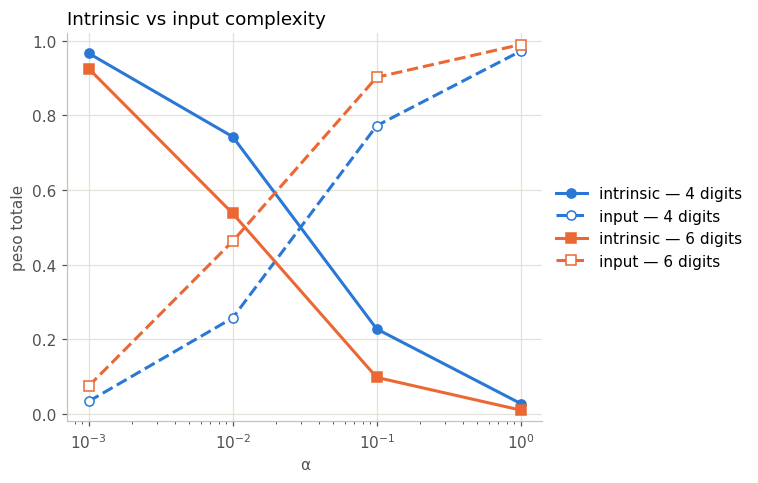

In [7]:
def plot_totali(tot):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for res, g in tot.groupby("res"):
        g = g.sort_values("alpha")
        ax.plot(g["alpha"], g["intrinsic"], marker=RES_MARKER[res], ls="-",
                color=RES_COLOR[res], label=f"intrinsic — {res} digits")
        ax.plot(g["alpha"], g["input"], marker=RES_MARKER[res], ls="--",
                color=RES_COLOR[res], mfc="white", label=f"input — {res} digits")
    ax.set_xscale("log")
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("α")
    ax.set_ylabel("peso totale")
    ax.set_title("Intrinsic vs input complexity", loc="left")
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    fig.tight_layout()
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / "intrinsic_vs_input_vs_alpha.png", dpi=200)
    plt.show()

plot_totali(tot)